# Support Vector Regression (linear)

SVM idea applied to regression. Fit a line and surround it with a tube of half-width `epsilon`:

- points **inside** the tube cost nothing
- points **outside** cost their distance beyond the tube (linear, not squared)

```
lam/2 * ||w||^2  +  mean( max(0, |y − (w·x + b)| − epsilon) )
```

Only points on or outside the tube (the support vectors) affect the fit. Consequences: it ignores small noise, and a few extreme outliers pull far less than in least squares. `lam` plays the role of `1 / (C·n)` in scikit-learn's `SVR`.

Linear kernel only here (see `16_svm` for the classifier). Scale features and `y`, since `epsilon` is measured in `y`'s units.

## Usage

```python
# (the class is defined in the Implementation section below)

model = LinearSVR(epsilon=0.1, lam=0.001).fit(X_train, y_train)
preds = model.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class LinearSVR:
    """Linear support vector regression: fit a line with a tube of half-width `epsilon` around it.
    Errors inside the tube cost nothing; outside, they cost linearly. Minimizes

        lam/2 * ||w||^2 + mean(max(0, |y - (Xw + b)| - epsilon))

    by full-batch subgradient descent. Scale features (and y, since epsilon is in y's units).

    ponytail: linear kernel only, no SMO / dual solver. Add kernels when needed."""

    def __init__(self, epsilon=0.1, lam=0.001, lr=0.1, n_iters=2000):
        self.epsilon = epsilon
        self.lam = lam
        self.lr = lr
        self.n_iters = n_iters
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n = len(y)
        self.weights = np.zeros(X.shape[1])
        self.bias = y.mean()  # start at the mean: the tube only cares about the shape from there

        for t in range(self.n_iters):
            residual = y - (X @ self.weights + self.bias)
            direction = np.sign(residual) * (np.abs(residual) > self.epsilon)  # 0 inside the tube
            grad_w = self.lam * self.weights - (X.T @ direction) / n
            grad_b = -direction.sum() / n
            step = self.lr / np.sqrt(t + 1)
            self.weights -= step * grad_w
            self.bias -= step * grad_b
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.weights + self.bias

## See it work

### 1. The ε-insensitive tube

SVR ignores errors smaller than `epsilon`: points *inside* the tube cost nothing, points outside pay a linear penalty. Only points on or outside the tube edges (the support vectors) influence the fit. The wider the tube, the fewer points matter and the flatter the fit.

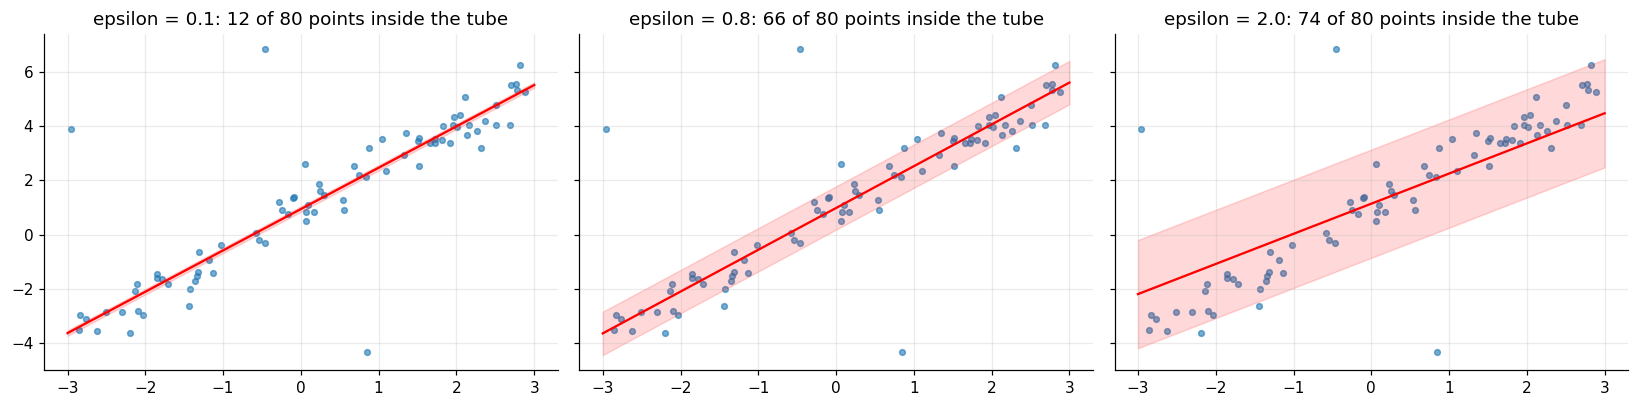

In [3]:
rng = np.random.default_rng(1)
x = rng.uniform(-3, 3, 80)
y = 1.5 * x + 1 + rng.normal(scale=0.6, size=80); y[[5, 40, 61]] += [6, -7, 8]   # three outliers
xs = np.linspace(-3, 3, 100)[:, None]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, eps in zip(axes, [0.1, 0.8, 2.0]):
    m = LinearSVR(epsilon=eps, lam=0.001, n_iters=3000).fit(x[:, None], y)
    pred = m.predict(xs)
    ax.scatter(x, y, s=14, alpha=0.6); ax.plot(xs, pred, "r"); ax.fill_between(xs[:, 0], pred - eps, pred + eps, color="r", alpha=0.15)
    inside = np.abs(y - m.predict(x[:, None])) <= eps
    ax.set_title(f"epsilon = {eps}: {inside.sum()} of 80 points inside the tube")
plt.tight_layout(); plt.show()

### 2. Robust to outliers (compared with least squares)

The epsilon-insensitive loss grows only linearly outside the tube, while squared error grows quadratically, so a few extreme points drag the OLS line much more.

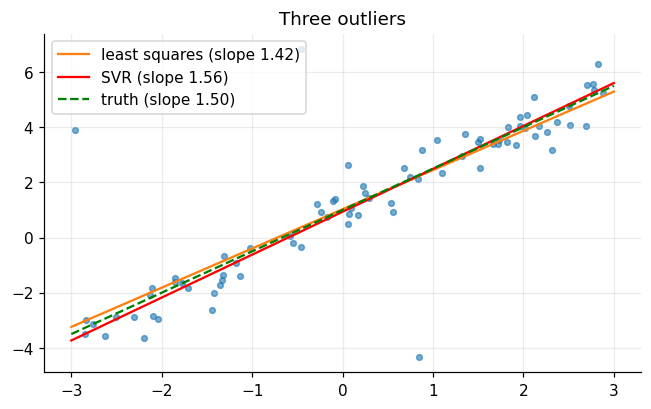

In [4]:
import sys
ols_w, ols_b = np.polyfit(x, y, 1)
svr = LinearSVR(epsilon=0.3, lam=0.001, n_iters=3000).fit(x[:, None], y)
plt.figure(figsize=(7, 4))
plt.scatter(x, y, s=14, alpha=0.6); plt.plot(xs, ols_w * xs[:, 0] + ols_b, "C1", label=f"least squares (slope {ols_w:.2f})")
plt.plot(xs, svr.predict(xs), "r", label=f"SVR (slope {svr.weights[0]:.2f})"); plt.plot(xs, 1.5 * xs[:, 0] + 1, "g--", label="truth (slope 1.50)")
plt.legend(); plt.title("Three outliers"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [5]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

X, y = make_regression(n_samples=400, n_features=5, n_informative=3, noise=10.0, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

x_scaler = StandardScaler().fit(X_train)
X_train, X_test = x_scaler.transform(X_train), x_scaler.transform(X_test)
y_std = y_train.std()
y_train, y_test = y_train / y_std, y_test / y_std  # epsilon is in y's units: put y on unit scale

C, epsilon = 10.0, 0.1
ours = LinearSVR(epsilon=epsilon, lam=1 / (C * len(y_train)), n_iters=3000).fit(X_train, y_train)
theirs = SVR(kernel="linear", C=C, epsilon=epsilon).fit(X_train, y_train)  # lam = 1 / (C * n)

mse_ours = np.mean((ours.predict(X_test) - y_test) ** 2)
mse_theirs = np.mean((theirs.predict(X_test) - y_test) ** 2)
print("test MSE (y scaled): ours=%.4f sklearn=%.4f" % (mse_ours, mse_theirs))
print("weights ours   :", np.round(ours.weights, 3))
print("weights sklearn:", np.round(theirs.coef_[0], 3))
assert abs(mse_ours - mse_theirs) < 0.01

test MSE (y scaled): ours=0.0328 sklearn=0.0328
weights ours   : [ 0.185 -0.012  0.718  0.76  -0.031]
weights sklearn: [ 0.186 -0.012  0.718  0.76  -0.031]


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [6]:
import numpy as np


def _line_data(noise=0.05):
    rng = np.random.default_rng(0)
    X = rng.uniform(-2, 2, size=(200, 1))
    y = 1.5 * X[:, 0] + 0.5 + rng.normal(scale=noise, size=200)
    return X, y


def test_recovers_a_line():
    X, y = _line_data()
    model = LinearSVR(epsilon=0.05, lam=1e-4, n_iters=3000).fit(X, y)
    assert abs(model.weights[0] - 1.5) < 0.1
    assert abs(model.bias - 0.5) < 0.1


def test_robust_to_outliers_unlike_least_squares():
    X, y = _line_data()
    y_bad = y.copy()
    y_bad[:5] += 50.0  # a few huge outliers
    svr = LinearSVR(epsilon=0.05, lam=1e-4, n_iters=3000).fit(X, y_bad)
    ols_slope = np.polyfit(X[:, 0], y_bad, 1)[0]
    # the linear (not squared) loss limits each outlier's pull
    assert abs(svr.weights[0] - 1.5) < abs(ols_slope - 1.5)


def test_wide_tube_ignores_small_noise():
    # every point sits inside a tube of half-width 5 around the mean: no gradient, no slope learned
    X, y = _line_data()
    model = LinearSVR(epsilon=5.0, lam=1e-4, n_iters=500).fit(X, y)
    assert abs(model.weights[0]) < 1e-9

In [7]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_recovers_a_line
PASS test_robust_to_outliers_unlike_least_squares
PASS test_wide_tube_ignores_small_noise

all 3 tests passed


## Takeaways

- **Use it when** you want a regression that tolerates small errors and is less sensitive to outliers; the kernelised form (not built here) handles curved relationships.
- **Parameters:** `epsilon` is the tube half-width *in the units of y* (so scale `y`), `lam ≈ 1/(C·n)` controls regularisation. Standardise features.
- **This version** is the linear SVR trained by subgradient descent on `λ/2‖w‖² + mean(max(0, |y − ŷ| − ε))`.
- **Interview line:** *"Fit a flat function with a ±ε no-penalty tube; errors beyond it cost linearly. The solution depends only on the support vectors."*